Image classification using deep neural networks. Example: Build a model to recognize handwritten digits (0–9) from grayscale images. Train and evaluate the model using fully connected neural networks and compare performance with CNN-based approaches. Use MNIST Dataset from Link: https://www.kaggle.com/datasets/hojjatk/mnist-dataset

### Importing libraries and dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.layers import Conv2D, MaxPooling2D

import warnings
warnings.filterwarnings("ignore")

In [2]:
from tensorflow.keras.datasets import mnist

# Load dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Save dataset
np.savez(
    "mnist_dataset.npz",
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test
)

print("MNIST dataset saved successfully!")

MNIST dataset saved successfully!


### Training and testing

Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)


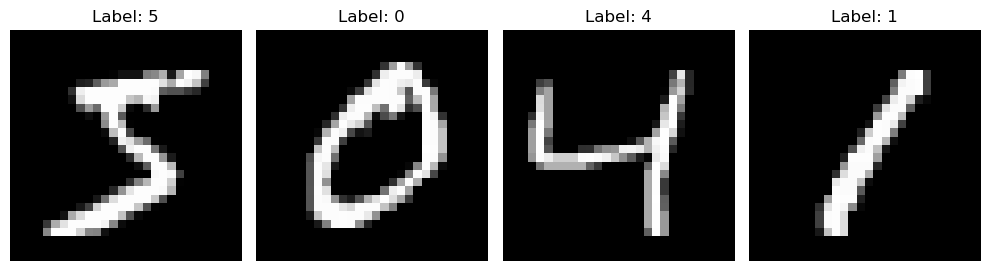

In [3]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

X_train = X_train / 255.0
X_test = X_test / 255.0

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

plt.figure(figsize=(10, 3))
for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
data = np.load("mnist_dataset.npz")

x_train = data["x_train"]
y_train = data["y_train"]
x_test = data["x_test"]
y_test = data["y_test"]

In [5]:
y_test

array([7, 2, 1, ..., 4, 5, 6], dtype=uint8)

### One hot encoding

In [6]:
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

In [7]:
# Load dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Normalize images
X_train = X_train / 255.0
X_test = X_test / 255.0

# One-hot encoding
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# Build DNN model
model = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

# Compile model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Train model
model.fit(X_train, y_train,
          epochs=10,
          batch_size=32,
          validation_split=0.2)

# Evaluate
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", accuracy*100)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9215 - loss: 0.2665 - val_accuracy: 0.9571 - val_loss: 0.1413
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9659 - loss: 0.1134 - val_accuracy: 0.9651 - val_loss: 0.1141
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9762 - loss: 0.0769 - val_accuracy: 0.9659 - val_loss: 0.1164
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9815 - loss: 0.0588 - val_accuracy: 0.9721 - val_loss: 0.0969
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9858 - loss: 0.0458 - val_accuracy: 0.9740 - val_loss: 0.0995
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9870 - loss: 0.0398 - val_accuracy: 0.9730 - val_loss: 0.1019
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9901 - loss: 0.0296 - val_accuracy: 0.9738 - val_loss: 0.1002
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9910 - loss: 0.0270 - 

### CNN

In [8]:
# Load dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Normalize
X_train = X_train / 255.0
X_test = X_test / 255.0

# Reshape for CNN
X_train = X_train.reshape(-1,28,28,1)
X_test = X_test.reshape(-1,28,28,1)

# One-hot encoding
y_train = to_categorical(y_train,10)
y_test = to_categorical(y_test,10)

# CNN Model
model = Sequential([
    Conv2D(32,(3,3),activation='relu',input_shape=(28,28,1)),
    MaxPooling2D((2,2)),
    
    Conv2D(64,(3,3),activation='relu'),
    MaxPooling2D((2,2)),
    
    Flatten(),
    Dense(128,activation='relu'),
    Dense(10,activation='softmax')
])

# Compile
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Train
model.fit(X_train,y_train,
          epochs=10,
          batch_size=32,
          validation_split=0.2)

# Test
loss,accuracy=model.evaluate(X_test,y_test)

print("CNN Accuracy:",accuracy*100)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - accuracy: 0.9549 - loss: 0.1466 - val_accuracy: 0.9809 - val_loss: 0.0627
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.9839 - loss: 0.0500 - val_accuracy: 0.9878 - val_loss: 0.0411
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - accuracy: 0.9895 - loss: 0.0330 - val_accuracy: 0.9861 - val_loss: 0.0439
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 17s 12ms/step - accuracy: 0.9923 - loss: 0.0235 - val_accuracy: 0.9881 - val_loss: 0.0378
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.9939 - loss: 0.0179 - val_accuracy: 0.9902 - val_loss: 0.0349
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.9950 - loss: 0.0136 - val_accuracy: 0.9883 - val_loss: 0.0454
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.9964 - loss: 0.0103 - val_accuracy: 0.9878 - val_loss: 0.0463
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.9962 -